<a href="https://colab.research.google.com/github/rajkumarsingh19/LLM_usecase/blob/main/Combining_LLM_Embeddings_with_Tabular_Features_in_a_Unified_Scikit_learn_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

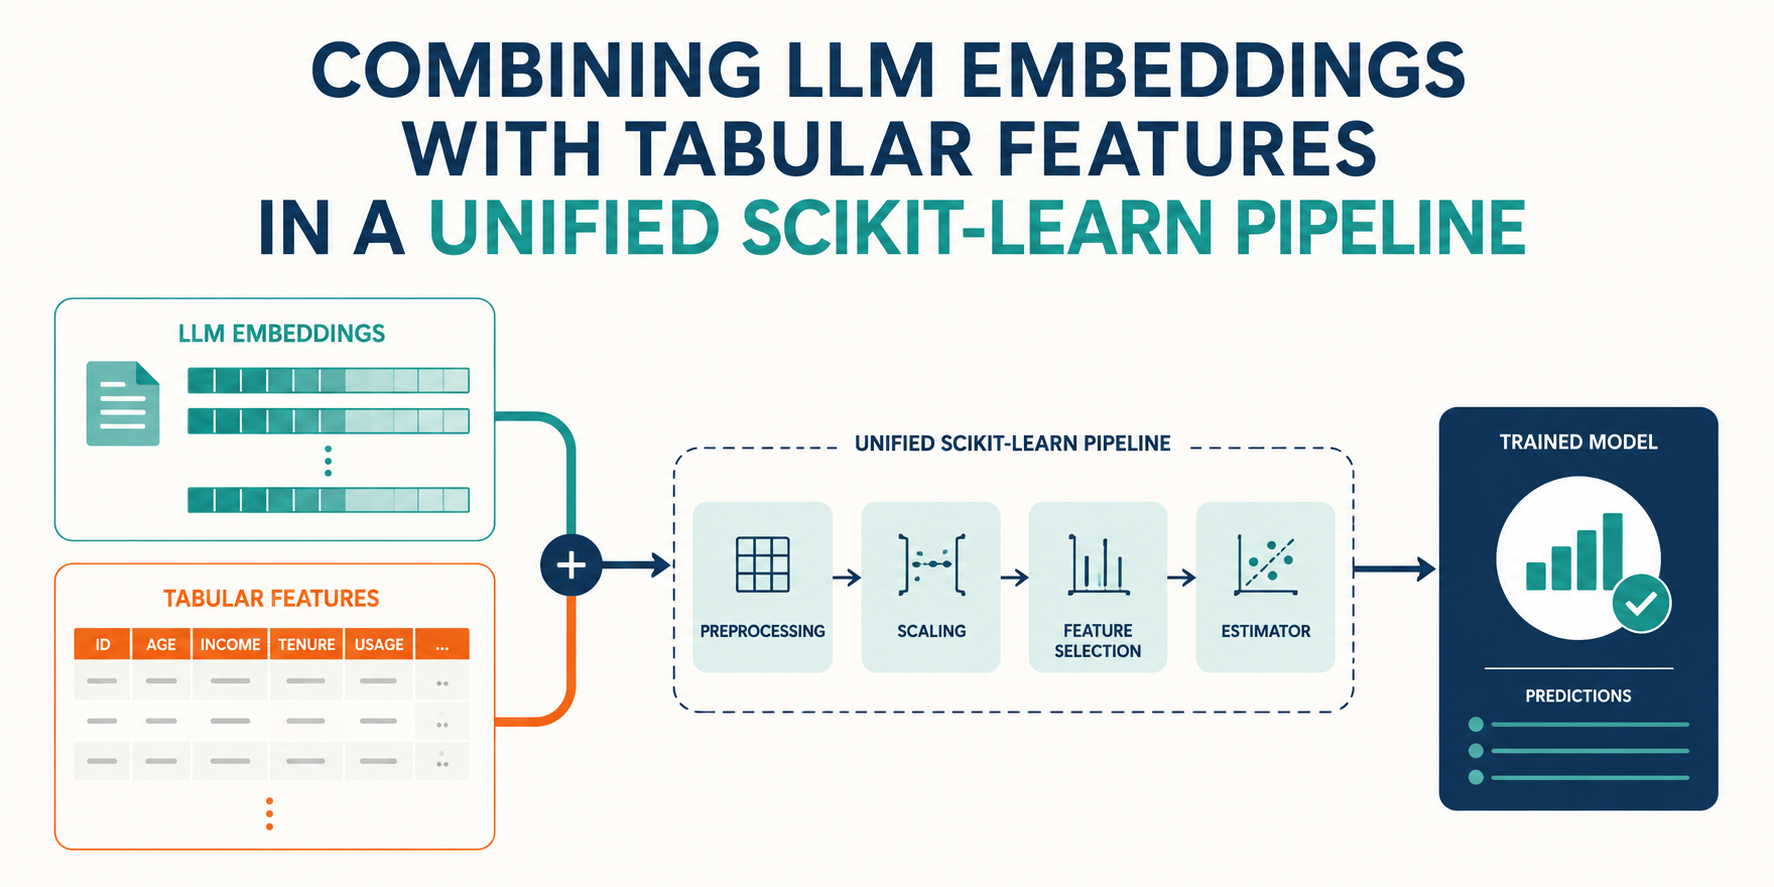

In [ ]:
!pip install -q sentence-transformers scikit-learn pandas numpy

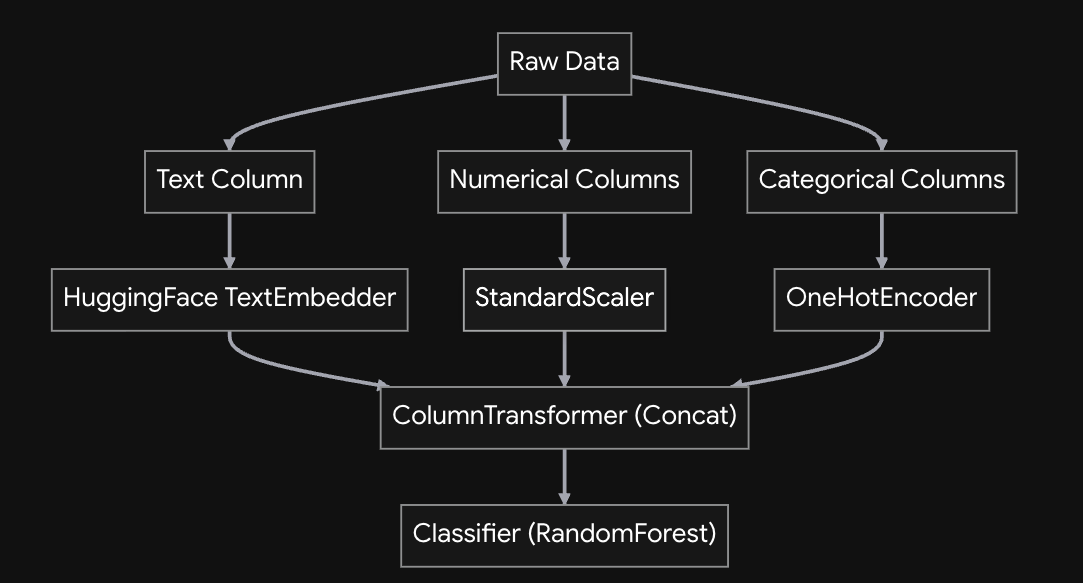

In [ ]:
import pandas as pd
import numpy as np

# 1. Loading base text dataset from GitHub
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(url, sep='\t', header=None, names=['label', 'message'])

# 2. Encoding original target variable first (0 for normal/ham, 1 for spam)
df['target'] = df['label'].map({'ham': 0, 'spam': 1})

# 3. Synthesising meaningful tabular features WITH realistic overlap (noise)
# Without noise and some degree of overlap, the classifier we will build would
# easily achieve perfection: something not quite realistic in practice.
np.random.seed(42)

# Account Age: Normal users can be brand new, and spammers sometimes use older hacked accounts
df['account_age_days'] = np.where(
    df['target'] == 1,
    np.random.randint(1, 365, df.shape[0]),       # Spam: 1 to 365 days
    np.random.randint(1, 1500, df.shape[0])       # Ham: 1 to 1500 days (Massive overlap)
)

# Premium Status: Adding a bit more noise here
df['is_premium'] = np.where(
    df['target'] == 1,
    np.random.choice(['no', 'yes'], df.shape[0], p=[0.95, 0.05]), # Spam: 95% free
    np.random.choice(['no', 'yes'], df.shape[0], p=[0.80, 0.20])  # Ham: 80% free, 20% premium
)

# Priority Score: Overlapping distributions so the model can't rely on this feature alone to classify customers
df['priority_score'] = np.where(
    df['target'] == 1,
    np.random.uniform(0.4, 1.0, df.shape[0]),   # Spam: 0.4 to 1.0
    np.random.uniform(0.0, 0.7, df.shape[0])    # Ham: 0.0 to 0.7 (Overlap between 0.4 and 0.7)
)

# Viewing a sample of the logically cohesive mixed data
df.head(5)

,label,message,target,account_age_days,is_premium,priority_score
0,ham,"Go until jurong point, crazy.. Available only ...",0,283,no,0.343945
1,ham,Ok lar... Joking wif u oni...,0,591,yes,0.420358
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,271,yes,0.939700
3,ham,U dun say so early hor... U c already then say...,0,1287,yes,0.569249
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,703,no,0.423007


In [ ]:
df['label'].value_counts().reset_index()


,label,count
0,ham,4825
1,spam,747


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sentence_transformers import SentenceTransformer

class TextEmbedder(BaseEstimator, TransformerMixin):
    def __init__(self, model_name='all-MiniLM-L6-v2'):
        self.model_name = model_name
        self.model = None

    def fit(self, X, y=None):
        # Initializing the model in fit() to comply with sklearn cloning rules
        if self.model is None:
            self.model = SentenceTransformer(self.model_name)
        return self

    def transform(self, X, y=None):
        # Handling pandas DataFrame (extract the first column as a list of strings)
        if isinstance(X, pd.DataFrame):
            texts = X.iloc[:, 0].astype(str).tolist()
        else:
            texts = pd.Series(X).astype(str).tolist()

        # Using the specified LLM, generate and return embeddings as a 2D numpy array
        return self.model.encode(texts, show_progress_bar=False)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Split data
X = df[['message', 'account_age_days', 'priority_score', 'is_premium']]
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define column groups
text_features = ['message']
numeric_features = ['account_age_days', 'priority_score']
categorical_features = ['is_premium']

# Build the ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TextEmbedder(), text_features),
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='drop' # Drop any columns not explicitly defined
)

# Assemble the final pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

In [ ]:
# Training the model (this will take a moment to download the HF model and embed the texts)
print("Training pipeline...")
pipeline.fit(X_train, y_train)

# Evaluating on test examples
print("Predicting and evaluating...")
y_pred = pipeline.predict(X_test)
print(classification_report(y_test, y_pred))

Training pipeline...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Predicting and evaluating...
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       966
           1       1.00      0.91      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.95      0.97      1115
weighted avg       0.99      0.99      0.99      1115



In [ ]:
confusion_matrix((y_test, y_pred))

array([[966,   0],
       [ 14, 135]])

In [ ]:
# Class 0 (Ham) Metrics
precision_class_0 = 966 / (966 + 14)
recall_class_0 = 966 / (966 + 0)

# Class 1 (Spam) Metrics
precision_class_1 = 135 / (135 + 0)
recall_class_1 = 135 / (135 + 14)

print(f"Class 0 (Ham)  -> Precision: {precision_class_0:.2%}, Recall: {recall_class_0:.2%}")
print(f"Class 1 (Spam) -> Precision: {precision_class_1:.2%}, Recall: {recall_class_1:.2%}")

Class 0 (Ham)  -> Precision: 98.57%, Recall: 100.00%
Class 1 (Spam) -> Precision: 100.00%, Recall: 90.60%


In [ ]:
# Verified calculations against the Classification Report
assert round(precision_class_0, 2) == 0.99
assert round(recall_class_0, 2) == 1.00
assert round(precision_class_1, 2) == 1.00
assert round(recall_class_1, 2) == 0.91
print("All manual metric calculations match the classification report perfectly!")

All manual metric calculations match the classification report perfectly!


In [ ]:
from sklearn.model_selection import cross_validate

# Performing 5-fold cross-validation
print("Running 5-fold cross-validation (this may take a minute due to embedding step)... ")
cv_results = cross_validate(
    pipeline,
    X,
    y,
    cv=5,
    scoring=['accuracy', 'f1_macro'],
    n_jobs=1,
    return_train_score=False
)

# Displaying the results
print("\nCross-Validation Results:")
print(f"Fold Accuracies: {cv_results['test_accuracy']}")
print(f"Mean Accuracy:   {cv_results['test_accuracy'].mean():.4f} (+/- {cv_results['test_accuracy'].std() * 2:.4f})")
print(f"Mean F1-Macro:   {cv_results['test_f1_macro'].mean():.4f} (+/- {cv_results['test_f1_macro'].std() * 2:.4f})")

Running 5-fold cross-validation (this may take a minute due to embedding step)... 


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Cross-Validation Results:
Fold Accuracies: [0.99013453 0.98834081 0.98025135 0.97935368 0.98025135]
Mean Accuracy:   0.9837 (+/- 0.0092)
Mean F1-Macro:   0.9627 (+/- 0.0221)
